In [1]:
import warnings

with warnings.catch_warnings():
    warnings.simplefilter(action="ignore", category=FutureWarning)

    import numpy as np
    import pandas as pd
    import scanpy as sc

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
adata = sc.read_h5ad(
    ".././0.1_adata_downsampled.h5ad"
)
obs = pd.read_csv(
    ".././0_adata obs - reduced and filt.csv",
    index_col=0,
)
adata = adata[obs.index].copy()
adata.obs = obs.loc[adata.obs_names].copy()
sc.pp.filter_genes(adata, min_cells=1)

print(adata)
adata.obs.head(2)

AnnData object with n_obs × n_vars = 1253024 × 43048
    obs: 'GSE_id', 'GSM_id', 'Age', 'Tissue_global', 'cell_type_final', 'Age_bin', 'cell_type', 'n_expr_genes'
    var: 'n_cells'


,GSE_id,GSM_id,Age,Tissue_global,cell_type_final,Age_bin,cell_type,n_expr_genes
AAACCTGAGGCCGAAT-1-GSM3758115,GSE130973,GSM3758115,25.0,Skin,Fibroblast,21,Fibroblasts,950
AAACCTGAGTTAAGTG-1-GSM3758115,GSE130973,GSM3758115,25.0,Skin,CD8T,21,CD8 T cells,1247


In [4]:
auc_scores = pd.read_csv(
    ".././1_dw_all_aucell_scores_1000.csv",
    index_col=0,
)
auc_scores.head(2)

,FRIDMAN_SENESCENCE_UP,cellage,senmayo
AAACCTGGTCGTCTTC-1-GSM6614348,0.033015,0.040974,0.032009
AAATGCCTCAAGGCTT-1-GSM6614348,0.035164,0.052543,0.014658


In [6]:
ds_scores = pd.read_csv(
    ".././2_dw_obs_ds_only.csv",
    index_col=0,
)
ds_scores.head(2)

/tmp/ipykernel_2169/3515768922.py:1: DtypeWarning: Columns (9) have mixed types. Specify dtype option on import or set low_memory=False.
  ds_scores = pd.read_csv(


,GSE_id,GSM_id,Age,Tissue_global,cell_type_final,Age_bin,cell_type,n_expr_genes,b,ds
AAACCTGGTCGTCTTC-1-GSM6614348,GSE214695,GSM6614348,61.0,Colon,B cell,61,B cells,1350,GSE214695,-1.860259
AAATGCCTCAAGGCTT-1-GSM6614348,GSE214695,GSM6614348,61.0,Colon,B cell,61,B cells,1075,GSE214695,-0.384411


In [7]:
print(ds_scores.shape)
print(ds_scores.isna().sum())

(1253024, 10)
GSE_id                  0
GSM_id                  0
Age                     0
Tissue_global           0
cell_type_final         0
Age_bin                 0
cell_type               0
n_expr_genes            0
b                  613085
ds                      0
dtype: int64


In [8]:
sd_scores = pd.read_csv(
    ".././3_dw_SenCID_all_res.csv",
    index_col=0,
)
sd_scores.head(2)

,RecSID,rec_SID1,rec_SID2,rec_SID3,rec_SID4,rec_SID5,rec_SID6,SID1_SID_Score,SID1_Decision,SID2_SID_Score,SID2_Decision,SID3_SID_Score,SID3_Decision,SID4_SID_Score,SID4_Decision,SID5_SID_Score,SID5_Decision,SID6_SID_Score,SID6_Decision
_index,,,,,,,,,,,,,,,,,,,
AAACCTGCAAGTCTGT-1-GSM6614348,SID3,-0.234518,0.770995,5.260713,4.133683,3.031912,2.056199,0.847145,0.610615,0.055487,-1.519336,0.952398,0.835413,0.933199,1.385414,0.089315,-0.444679,0.417053,-0.204920
AAACGGGGTCTAGCCG-1-GSM6614348,SID3,-0.246285,0.789723,5.262357,2.053069,4.067747,3.094766,0.997583,1.950533,0.119052,-1.034661,0.961493,0.996402,0.691206,0.525196,0.499292,0.087202,0.429437,0.006668


In [9]:
sd_scores["sid_score"] = sd_scores.apply(
    lambda row: row.get(f"{row['RecSID']}_SID_Score", np.nan), axis=1
)
sd_scores_rec = sd_scores[["RecSID", "sid_score"]].copy()

# 2. Присоединяем к adata.obs по индексу.  outer -> сохраняем строки из ОБОИХ датафреймов
obs_merged = adata.obs.merge(
    sd_scores_rec, left_index=True, right_index=True, how="outer"
)
print("adata.obs:", adata.obs.shape)
print("sd_scores:", sd_scores_rec.shape)
print("merged:", obs_merged.shape)

# 3. Удаляем строки без sid_score
obs_score = obs_merged.dropna(subset=["sid_score"]).copy()
print("После dropna по sid_score:", obs_score.shape)

print("\nКоличество NA по cell_type:")
print(obs_score["cell_type"].isna().sum())

adata.obs: (1253024, 8)
sd_scores: (1253024, 2)
merged: (1253024, 10)
После dropna по sid_score: (1253024, 10)

Количество NA по cell_type:
0


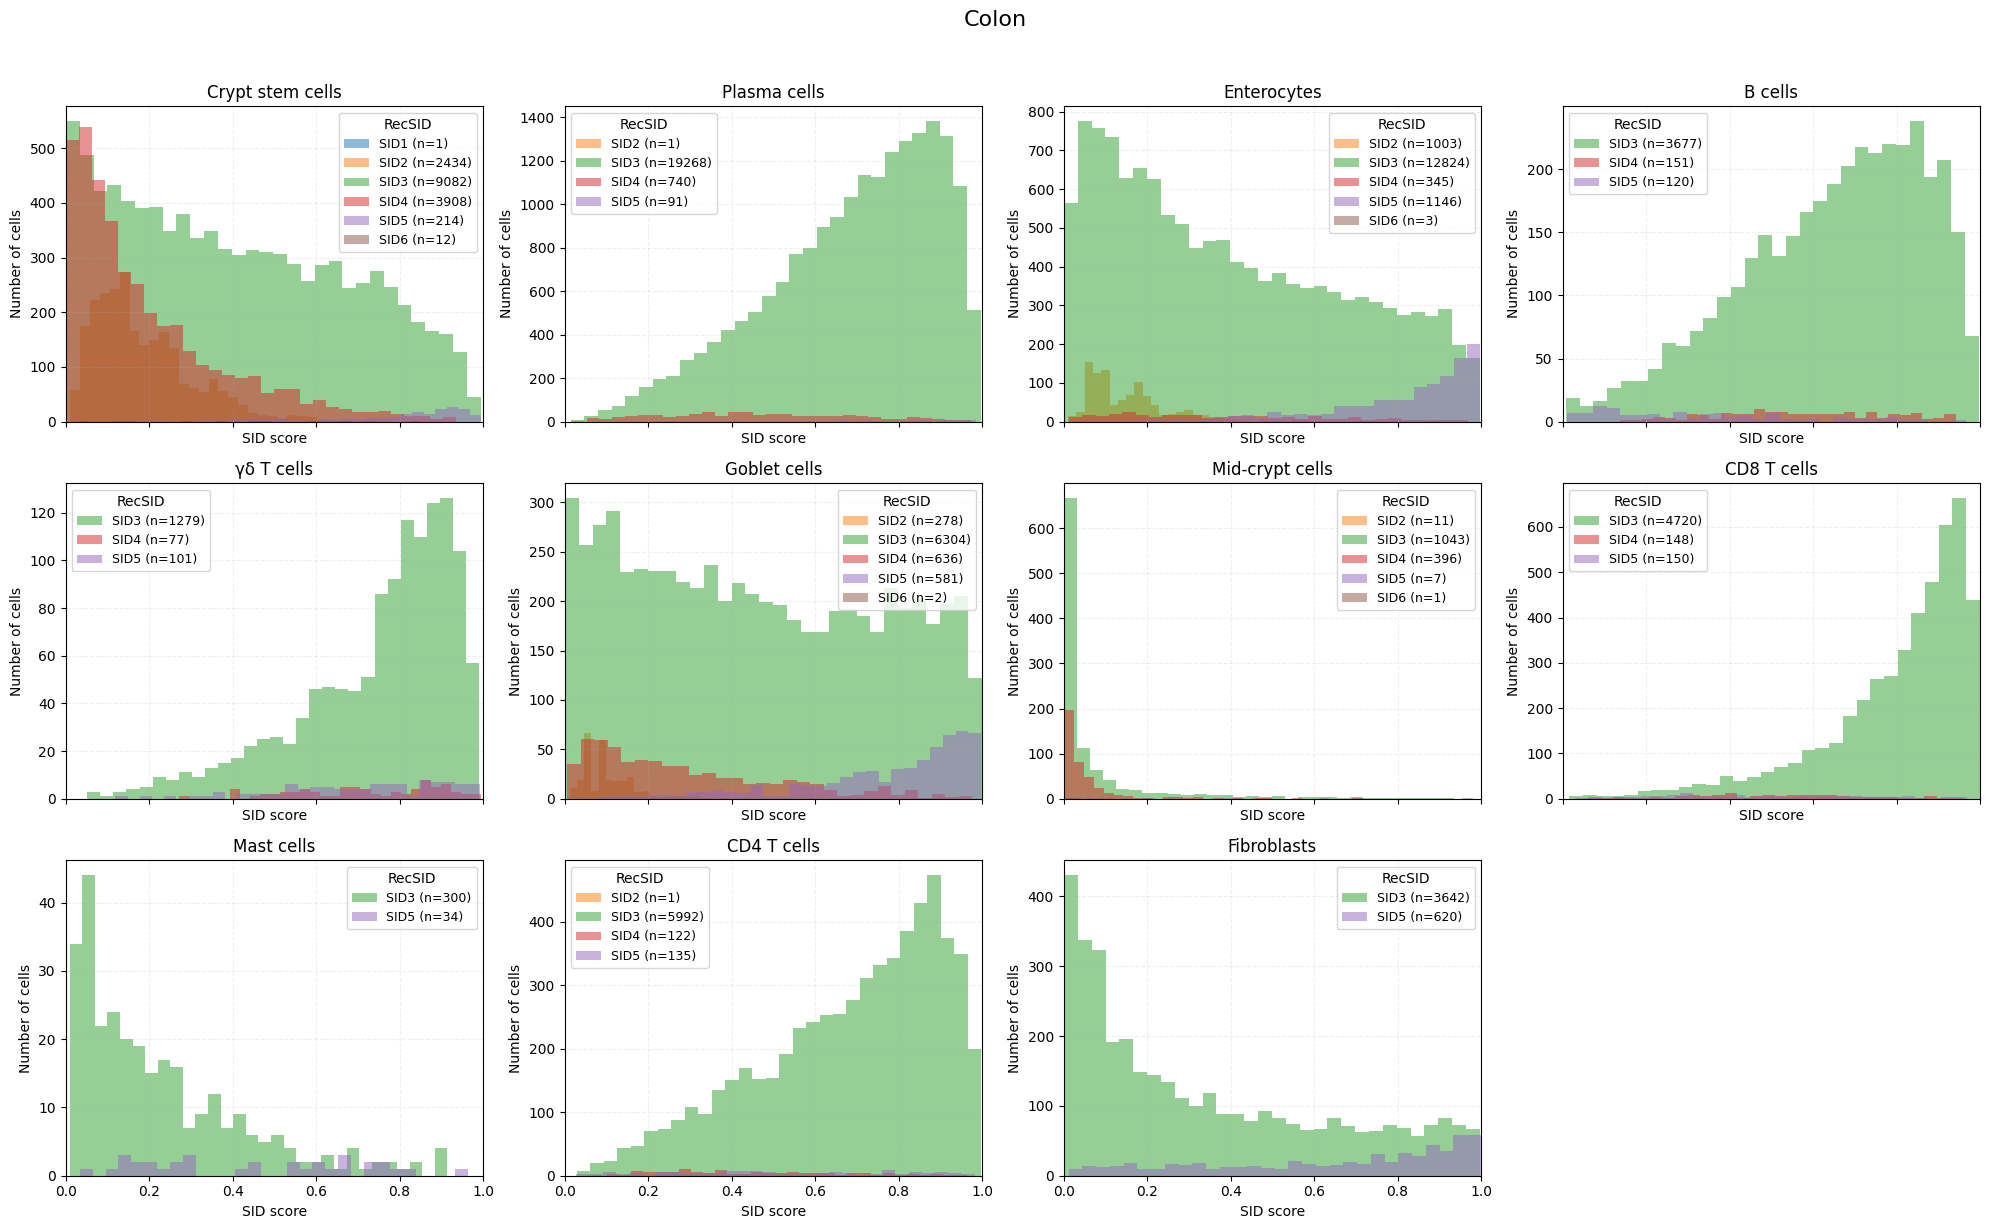

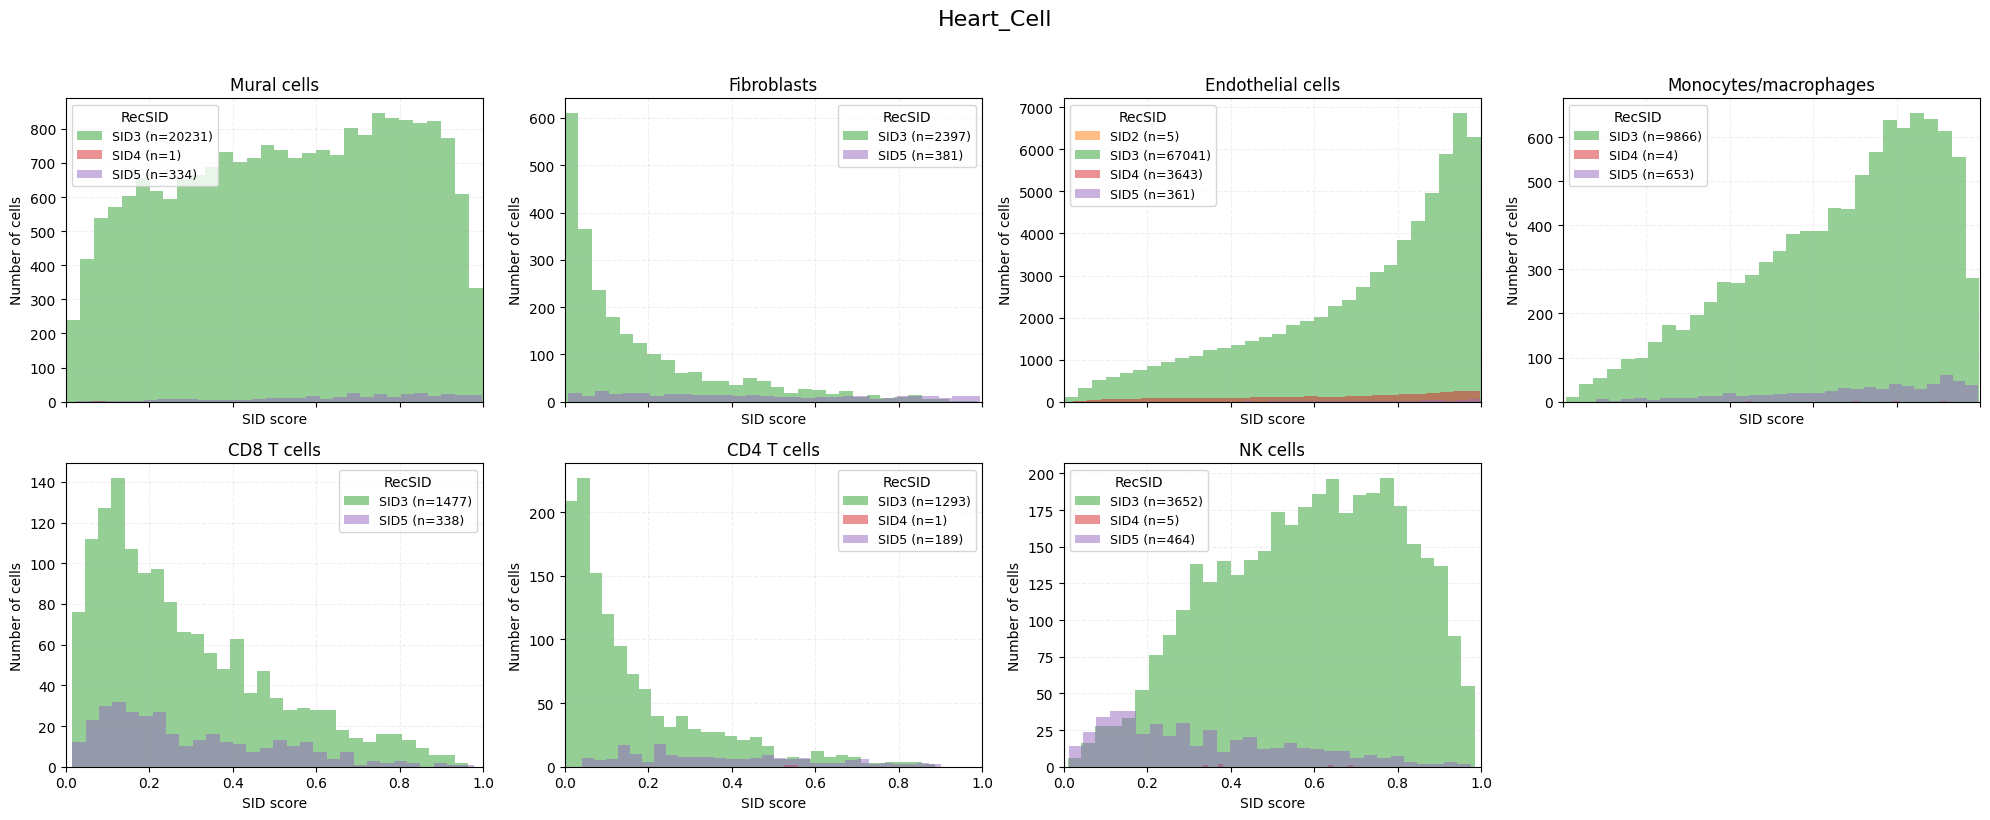

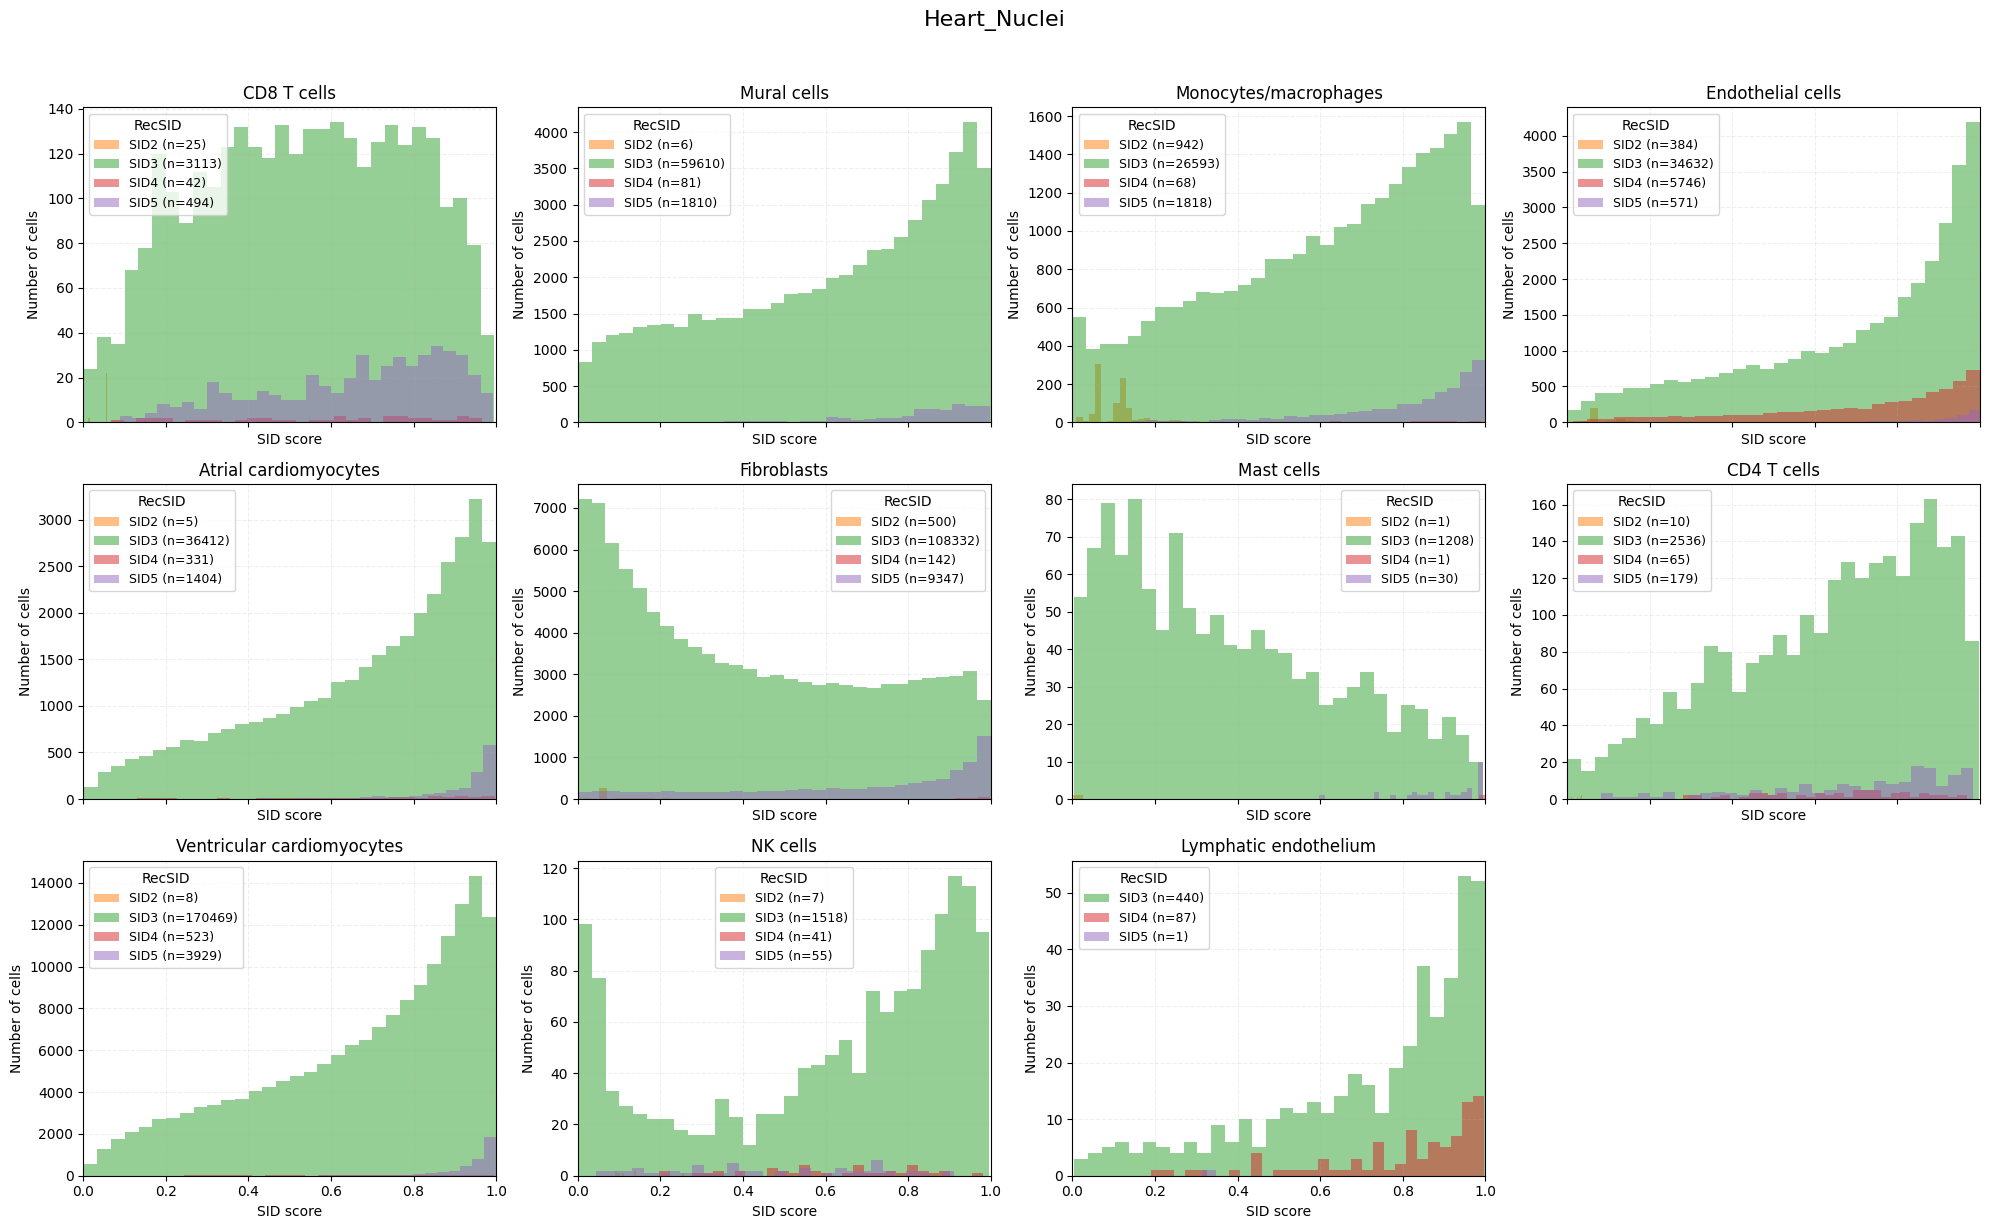

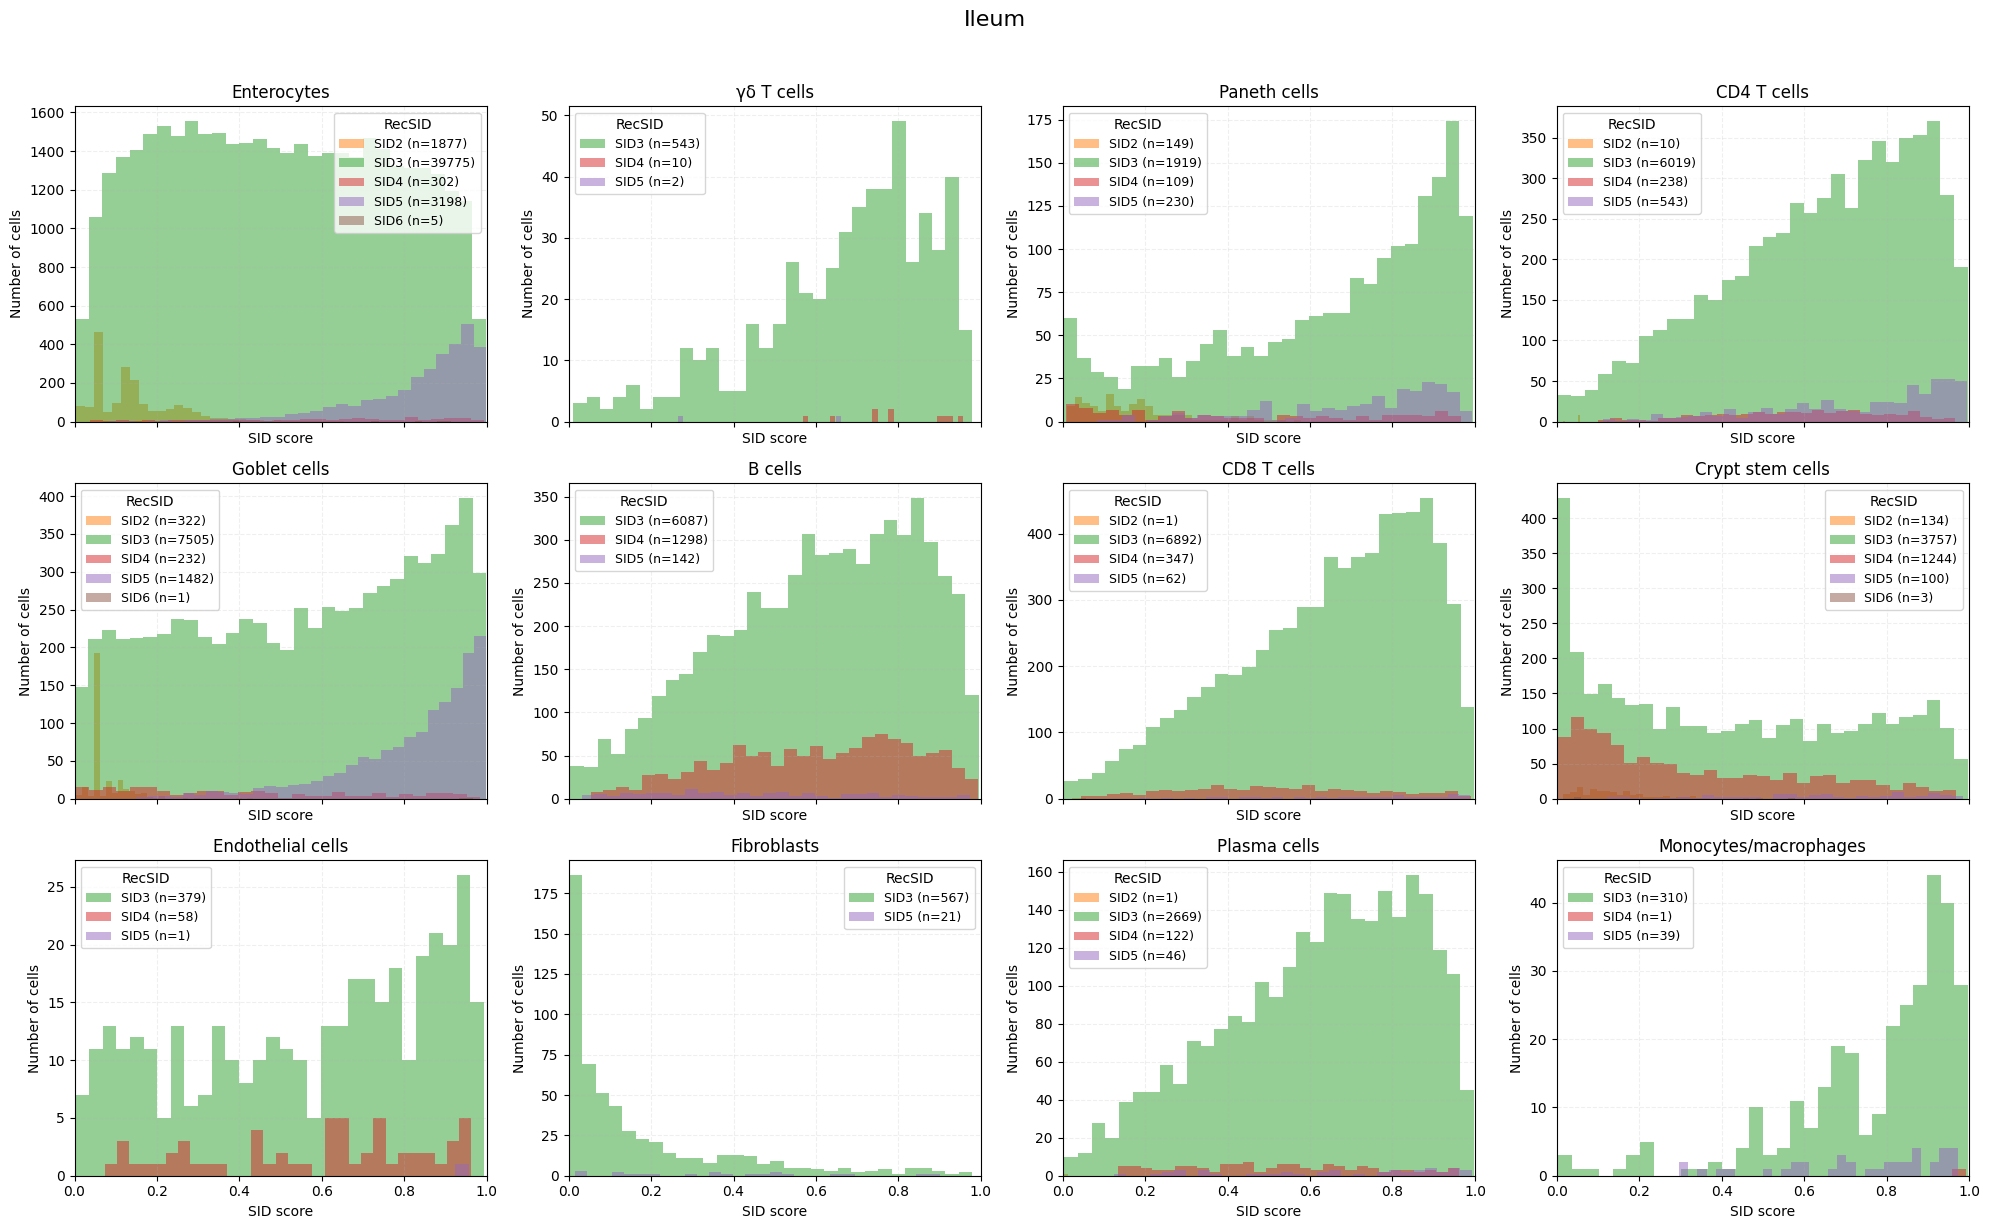

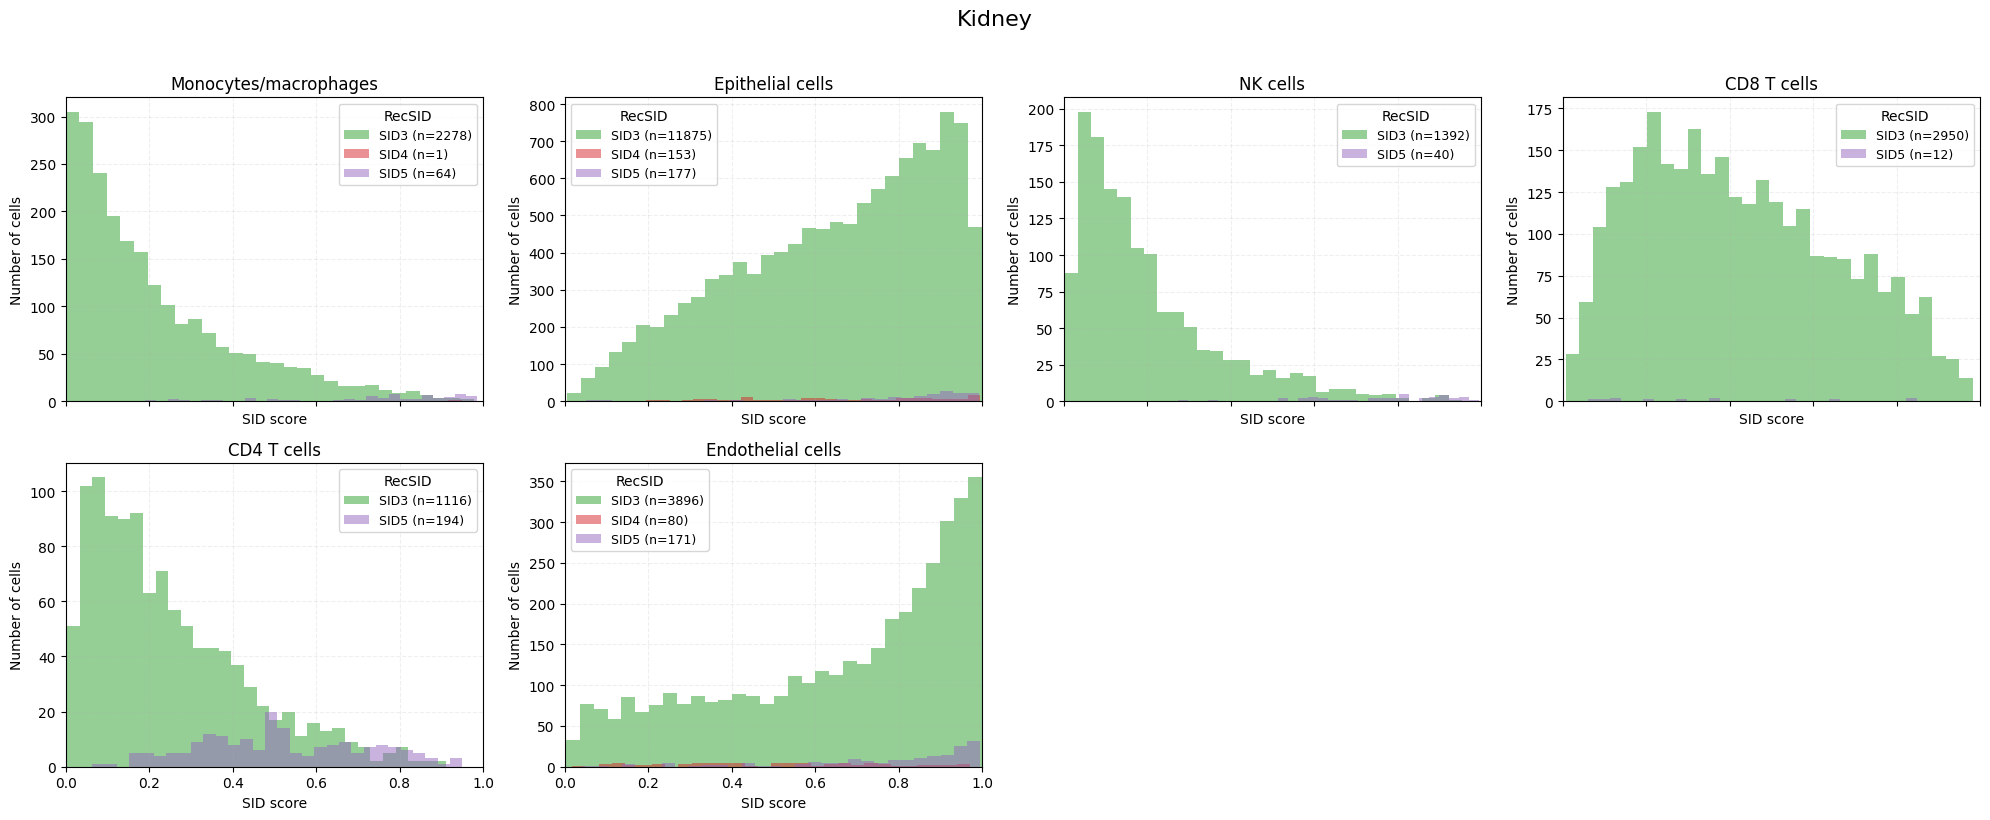

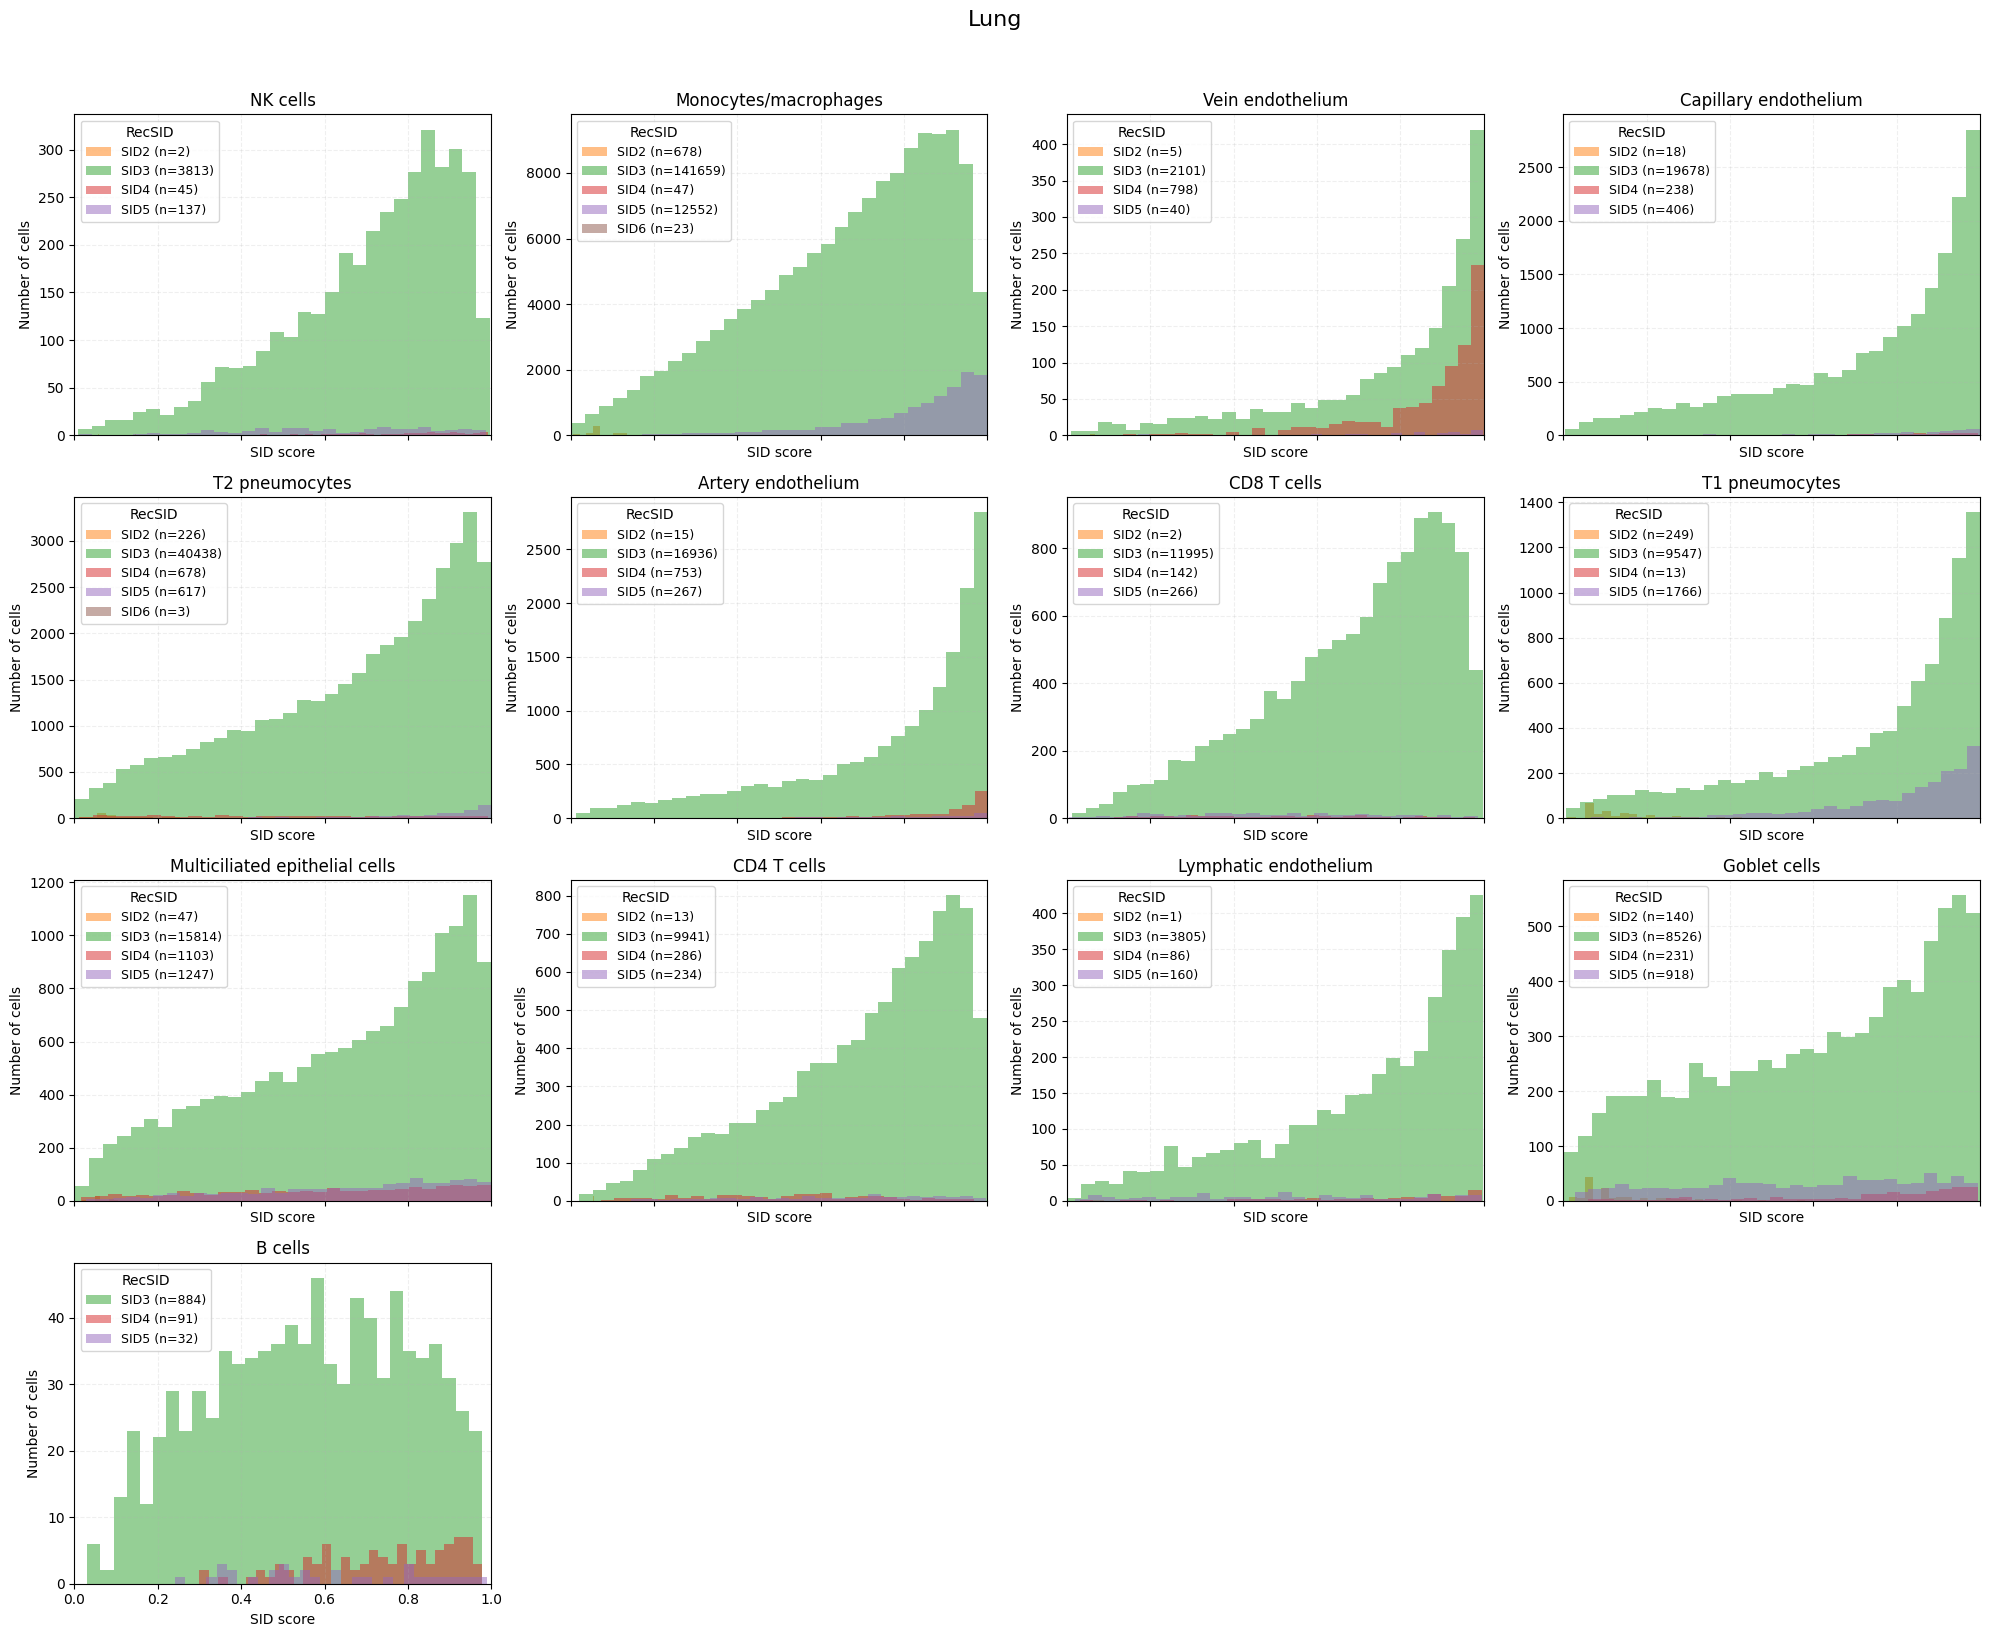

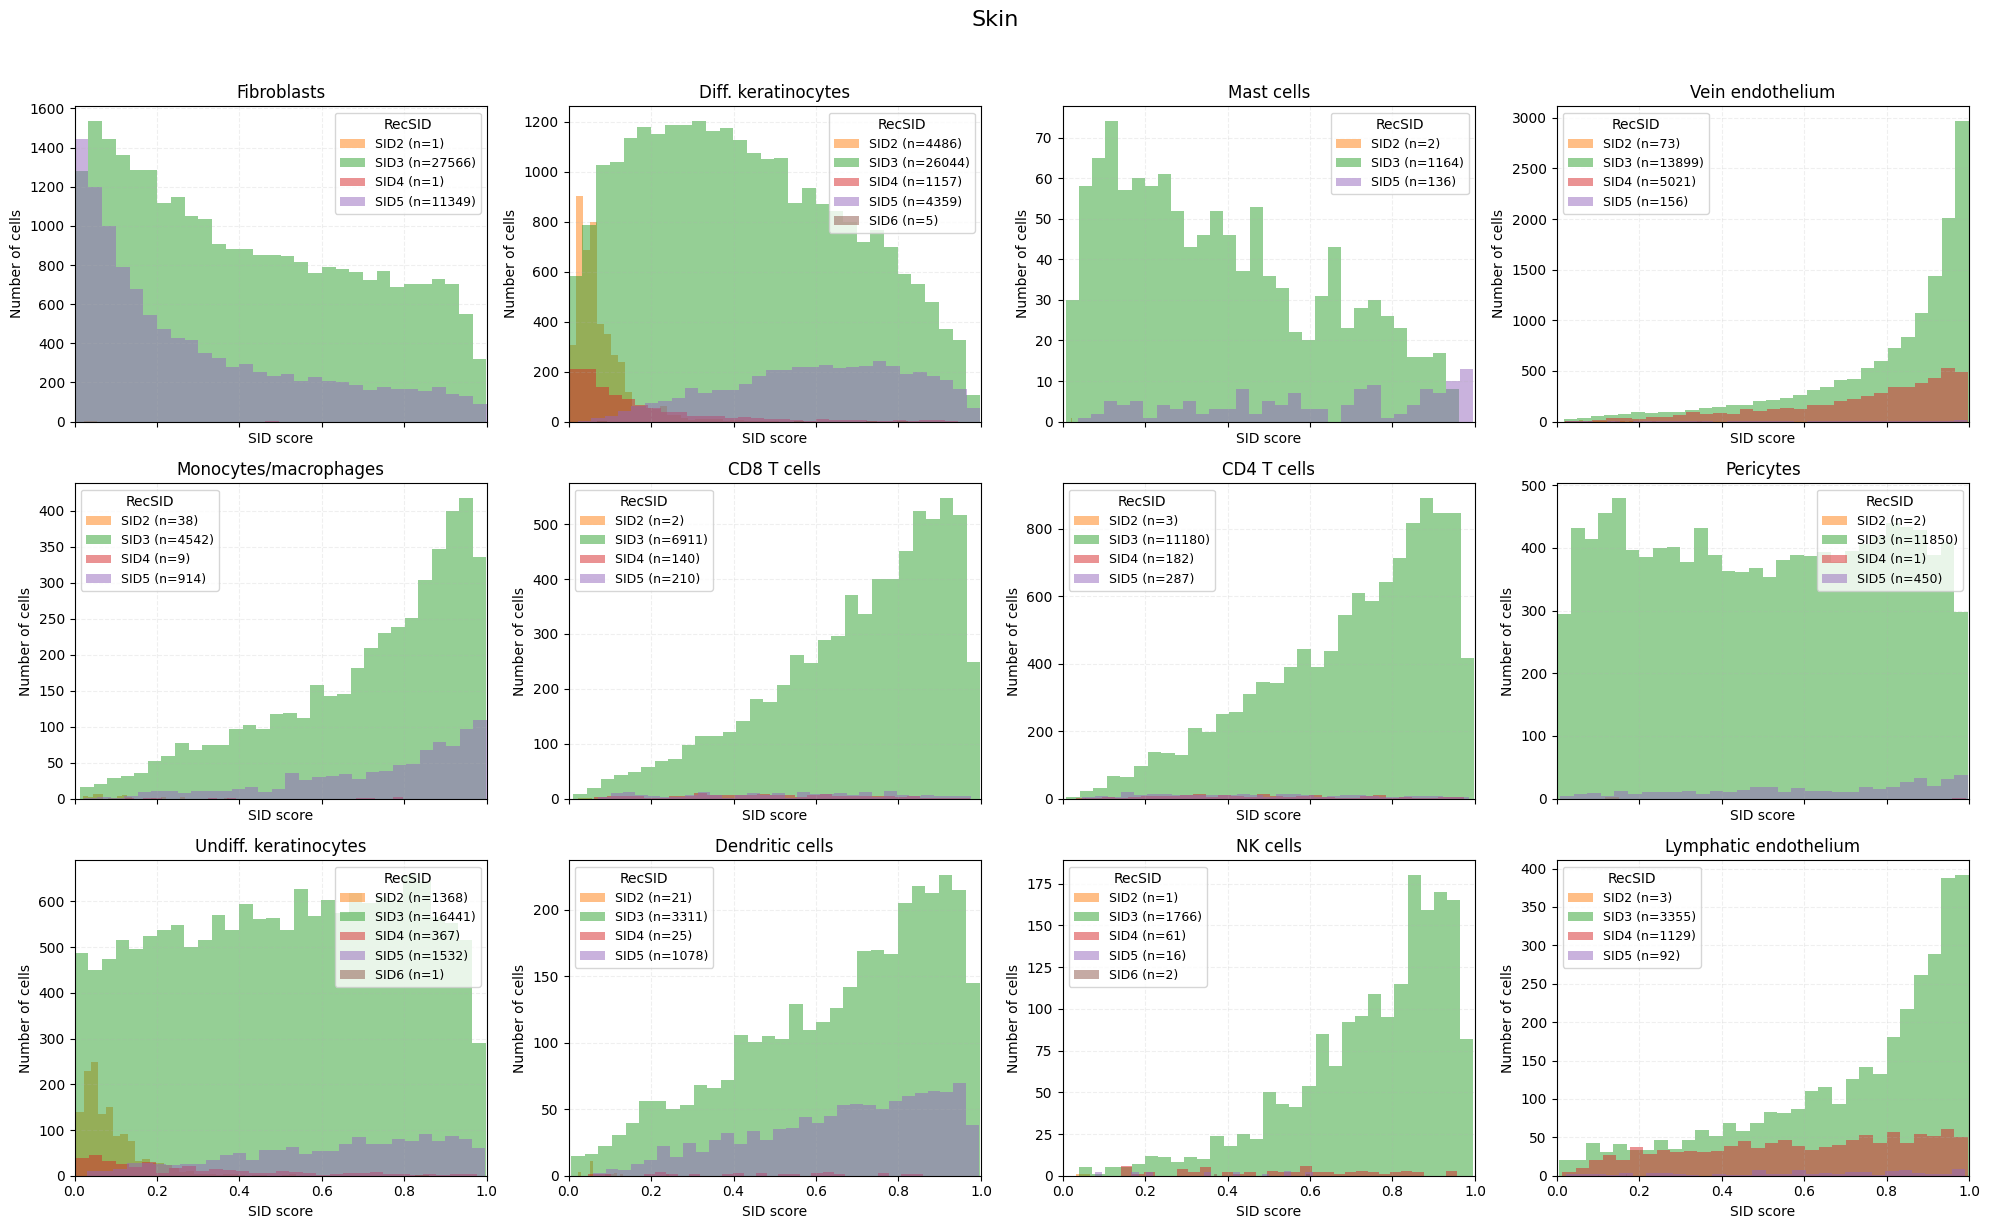

In [10]:
# Цвета для RecSID
rec_sids = sorted(obs_score["RecSID"].dropna().unique())
palette = dict(zip(rec_sids, sns.color_palette("tab10", n_colors=len(rec_sids))))


# Отдельная фигура для каждой ткани
n_cols = 4
for tissue, tissue_data in obs_score.groupby("Tissue_global", observed=True):
    # Уникальные cell types в данной ткани
    cell_types = tissue_data["cell_type"].dropna().unique()
    n_cell_types = len(cell_types)
    # Количество строк
    n_rows = int(np.ceil(n_cell_types / n_cols))

    # Создаём фигуру
    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(5 * n_cols, 4 * n_rows),
        sharex=True,
    )

    # Приводим axes к одномерному массиву
    axes = np.atleast_1d(axes).flatten()

    for ax, cell_type in zip(axes, cell_types):
        group = tissue_data[tissue_data["cell_type"] == cell_type]
        # Отдельная гистограмма для каждого RecSID
        for rec_sid, sub in group.groupby("RecSID", observed=True):
            ax.hist(
                sub["sid_score"],
                bins=30,
                alpha=0.5,
                color=palette[rec_sid],
                label=f"{rec_sid} (n={len(sub)})",
            )
        ax.set_xlim(0, 1)
        ax.set_title(cell_type)
        ax.set_xlabel("SID score")
        ax.set_ylabel("Number of cells")
        ax.legend(title="RecSID", fontsize=9)
        ax.grid(alpha=0.2, linestyle="--")

    for ax in axes[n_cell_types:]:
        fig.delaxes(ax)

    fig.suptitle(tissue, fontsize=16, y=1.02)

    plt.tight_layout()
    plt.show()

In [11]:
sp_scores = pd.read_csv(
    ".././0.2_sp_scores_dw.csv",
    index_col=0,
)
sp_scores.head(2)

,sp
AAACCTGAGGCCGAAT-1-GSM3758115,14.166038
AAACCTGAGTTAAGTG-1-GSM3758115,2.127291


In [14]:
# Названия ваших таблиц со скорами
score_tables = [sp_scores, sd_scores_rec, ds_scores, auc_scores]
cleaned_tables = []

for df in score_tables:
    # Оставляем колонку, если её нет в adata.obs ИЛИ это нужный вам FRIDMAN_SENESCENCE_UP
    cols_to_keep = [
        col for col in df.columns 
        if col not in adata.obs.columns
    ]
    # Добавляем отфильтрованный датафрейм в список
    cleaned_tables.append(df[cols_to_keep])

# Теперь join отработает без ошибок, так как дубликаты удалены
all_scores = adata.obs.join(cleaned_tables, how="left")

# Переименовываем целевую колонку
all_scores.rename(columns={"FRIDMAN_SENESCENCE_UP": "fridman", 'sid_score': 'sid'}, inplace=True)
print(all_scores.shape)
all_scores.head(3)


(1253024, 16)


,GSE_id,GSM_id,Age,Tissue_global,cell_type_final,Age_bin,cell_type,n_expr_genes,sp,RecSID,sid,b,ds,fridman,cellage,senmayo
AAACCTGAGGCCGAAT-1-GSM3758115,GSE130973,GSM3758115,25.0,Skin,Fibroblast,21.0,Fibroblasts,950.0,14.166038,SID3,0.773698,GSE130973,0.145985,0.195521,0.046323,0.124120
AAACCTGAGTTAAGTG-1-GSM3758115,GSE130973,GSM3758115,25.0,Skin,CD8T,21.0,CD8 T cells,1247.0,2.127291,SID3,0.607294,GSE130973,0.124610,0.080760,0.051311,0.040026
AAACCTGGTCTTCTCG-1-GSM3758115,GSE130973,GSM3758115,25.0,Skin,VE,21.0,Vein endothelium,724.0,1.607762,SID3,0.877589,GSE130973,0.482569,0.073341,0.071276,0.054778


In [15]:
all_scores.to_csv(
    ".././4.1_dw_all_sen_scores_obs.csv"
)